In [2]:
############## Compare the trends of wl and sa measurements over western and central SESE ######
import geopandas as gpd
import geopandas as gpd
from shapely.ops import unary_union, polygonize
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression
from scipy.stats import linregress

In [3]:
points = gpd.read_file("/Volumes/MaloneLab/Research/Whitezone/Result/Spatial_Modelling/Results/combo_salinity_points.shp")
# Ensure CRS is geographic (lat/lon), if not reproject to WGS84
if points.crs != "EPSG:4326":
    points = points.to_crs("EPSG:4326")

# Extract lat/lon
points["lon"] = points.geometry.x
points["lat"] = points.geometry.y

# Now you have a DataFrame with lat/lon
print(points[["lat", "lon"]].head())

# 2. Read transects shapefile
transects = gpd.read_file("/Volumes/MaloneLab/Research/Whitezone/Spatial_Data/transects_39_61.shp")

# Reproject if needed to match CRS
if transects.crs != "EPSG:4326":
    transects = transects.to_crs("EPSG:4326")

print(transects.head())

     lat        lon
0  25.22 -80.536581
1  25.14 -80.720000
2  25.18 -80.626919
3  25.25 -80.440000
4  25.23 -80.460000
   ID                                           geometry
0  39  LINESTRING (-80.43141 25.24549, -80.47312 25.3...
1  61  LINESTRING (-80.51986 25.22790, -80.55485 25.2...


In [4]:
####### Read in a csv and convert to shapefile ########
# import pandas as pd
# import geopandas as gpd
# from shapely.geometry import Point

# # Input and output paths
# csv_path = "/Users/bz294/Documents/WhiteZone/Data/Driver_Analysis/Salinity/combo_salinity.csv"
# shp_path = "/Volumes/MaloneLab/Research/Whitezone/Result/Spatial_Modelling/Results/combo_salinity_points.shp"

# # Read CSV
# df = pd.read_csv(csv_path)

# # Convert lat/lon columns to numeric (force errors to NaN, then drop those rows)
# df["lat"] = pd.to_numeric(df["lat"], errors="coerce")
# df["lon"] = pd.to_numeric(df["lon"], errors="coerce")
# df = df.dropna(subset=["lat", "lon"])

# # Create geometry
# geometry = [Point(xy) for xy in zip(df["lon"], df["lat"])]

# # Create GeoDataFrame
# gdf = gpd.GeoDataFrame(df, geometry=geometry, crs="EPSG:4326")  # WGS84

# # Export to shapefile
# gdf.to_file(shp_path, driver="ESRI Shapefile")

# print(f"Shapefile saved at: {shp_path}")


In [5]:
####### Grouping the stations into western and central SESE ##############
# Define station groups
west = [
    "FLAB12_salinity", 
    "FLAB11_salinity", 
    "FLAB10_salinity"
]

central = [
    "FLAB08_salinity", 
    "FLAB07_salinity", 
]

east = [
     "BISC00B_salinity", 
     "BISC06B_salinity", 
     "BISCA2_salinity", 
     "BISCA4_salinity"
]

In [6]:
### EDEN data org ######
salinity_df = pd.read_csv('/Volumes/MaloneLab/Research/Whitezone/Hydro_Salinity/Salinity/salinity_annual_avg.csv')

# Keep only specified sites
keep_sites = ['FLAB10_salinity', 'FLAB12_salinity', 'FLAB11_salinity', 'FLAB07_salinity', 'FLAB08_salinity', 'BISC00B_salinity', 'BISC06B_salinity', 'BISCA2_salinity', 'BISCA4_salinity']
salinity_df = salinity_df[salinity_df['site'].isin(keep_sites)]


# Convert types
salinity_df['year'] = salinity_df['year'].astype(int)
salinity_df = salinity_df[salinity_df['year'] != 2025]



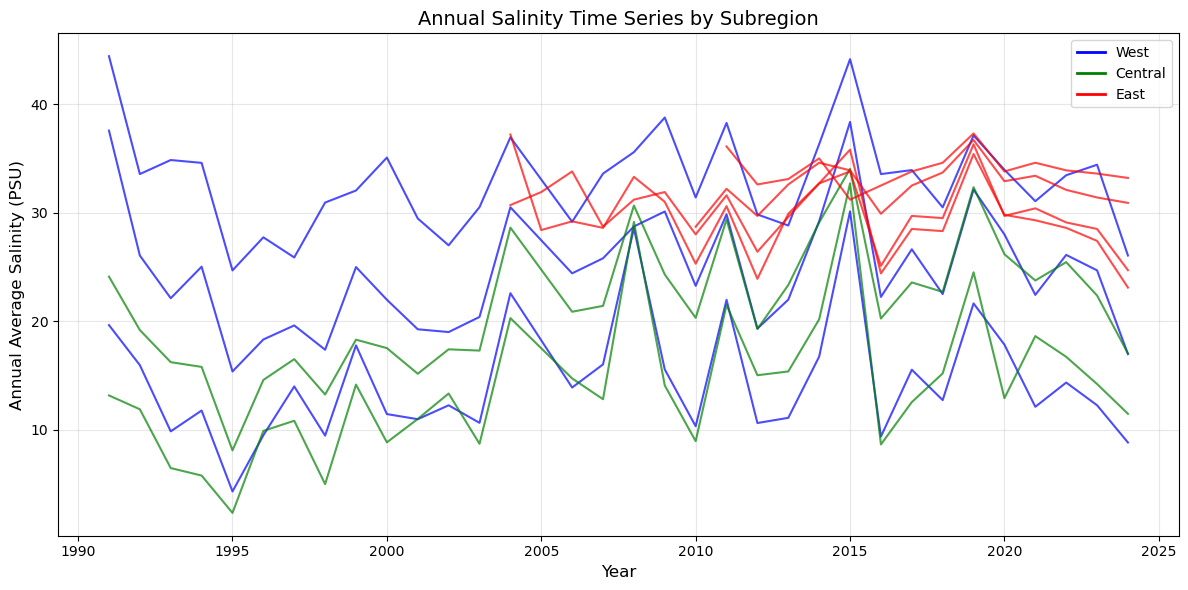

In [7]:
## plot by subregion ###
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 6))

# --- WEST ---
west_df = salinity_df[salinity_df["site"].isin(west)]
for station, subdf in west_df.groupby("site"):
    plt.plot(subdf["year"], subdf["annual_avg"], 
             color="blue", alpha=0.7, linewidth=1.5, label="_nolegend_")

# --- CENTRAL ---
central_df = salinity_df[salinity_df["site"].isin(central)]
for station, subdf in central_df.groupby("site"):
    plt.plot(subdf["year"], subdf["annual_avg"], 
             color="green", alpha=0.7, linewidth=1.5, label="_nolegend_")

# --- EAST ---
east_df = salinity_df[salinity_df["site"].isin(east)]
for station, subdf in east_df.groupby("site"):
    plt.plot(subdf["year"], subdf["annual_avg"], 
             color="red", alpha=0.7, linewidth=1.5, label="_nolegend_")

# Labels and title
plt.xlabel("Year", fontsize=12)
plt.ylabel("Annual Average Salinity (PSU)", fontsize=12)
plt.title("Annual Salinity Time Series by Subregion", fontsize=14)

# Custom legend
plt.plot([], [], color="blue", linewidth=2, label="West")
plt.plot([], [], color="green", linewidth=2, label="Central")
plt.plot([], [], color="red", linewidth=2, label="East")
plt.legend()

plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


In [8]:
## Baseline the start ####

# Filter years 2013–2024
test_df = salinity_df[(salinity_df["year"] >= 2013) & (salinity_df["year"] <= 2024)].copy()

# Baseline each station at 2013
baselined_list = []
for station, subdf in test_df.groupby("site"):
    subdf = subdf.copy()
    start_val = subdf[subdf["year"] == 2013]["annual_avg"].values
    if len(start_val) > 0:
        baseline = start_val[0]
        subdf["baseline"] = subdf["annual_avg"] - baseline
        baselined_list.append(subdf)

baselined_df = pd.concat(baselined_list)

# Assign region
def assign_region(site):
    if site in west:
        return "west"
    elif site in central:
        return "central"
    else:
        return "east"

baselined_df["region"] = baselined_df["site"].apply(assign_region)

# Calculate slope, p-value, r2 for each region
trends = {}
for region, subdf in baselined_df.groupby("region"):
    yearly_mean = subdf.groupby("year")["baseline"].mean().reset_index()
    slope, intercept, r_value, p_value, std_err = linregress(yearly_mean["year"], yearly_mean["baseline"])
    trends[region] = {"slope": slope, "p_value": p_value, "r2": r_value**2}

trend_df = pd.DataFrame(trends).T
print("Baselined Salinity Trends (2013-2024):")
print(trend_df)


Baselined Salinity Trends (2013-2024):
            slope   p_value        r2
central -0.530307  0.269955  0.120020
east    -0.215472  0.295855  0.108468
west    -0.514503  0.260705  0.124447


In [8]:
## De-mean ######

# Filter years 2013–2024
test_df = salinity_df[(salinity_df["year"] >= 2013) & (salinity_df["year"] <= 2024)].copy()

# Subtract station mean instead of 2013 baseline
demeaned_list = []
for station, subdf in test_df.groupby("site"):
    subdf = subdf.copy()
    mean_val = subdf["annual_avg"].mean()
    subdf["demeaned"] = subdf["annual_avg"] - mean_val
    demeaned_list.append(subdf)

demeaned_df = pd.concat(demeaned_list)

# Assign region
def assign_region(site):
    if site in west:
        return "west"
    elif site in central:
        return "central"
    else:
        return "east"

demeaned_df["region"] = demeaned_df["site"].apply(assign_region)

# Calculate slope, p-value, r2 for each region
trends = {}
for region, subdf in demeaned_df.groupby("region"):
    yearly_mean = subdf.groupby("year")["demeaned"].mean().reset_index()
    slope, intercept, r_value, p_value, std_err = linregress(yearly_mean["year"], yearly_mean["demeaned"])
    trends[region] = {"slope": slope, "p_value": p_value, "r2": r_value**2}

trend_df = pd.DataFrame(trends).T
print("Demeaned Salinity Trends (2013–2024):")
print(trend_df)


Demeaned Salinity Trends (2013–2024):
            slope   p_value        r2
central -0.530307  0.269955  0.120020
east    -0.215472  0.295855  0.108468
west    -0.514503  0.260705  0.124447
